# 07 — Fine-tuning : des comptines de 4 vers

Le modèle du notebook 06 écrit de l'anglais cohérent et utilise (un peu) les
mots-clés, mais il écrit des **histoires** : il n'a vu que TinyStories. Ce
notebook lui apprend la forme voulue : une **comptine de 4 vers courts**,
avec un peu de rime.

1. **Fine-tuning** : on continue l'entraînement sur les comptines de 4 lignes
   seulement. Le modèle garde l'anglais appris sur TinyStories et prend la
   forme des comptines.
2. **Génération** : arrêt après le 4ᵉ vers, et **meilleur de N** (on écrit
   plusieurs comptines pour la même consigne et on garde la meilleure).
3. **Comparaison finale** des quatre modèles du projet sur les comptines de
   validation.

In [1]:
import copy
import json
import math
import random
import shutil
import time
from contextlib import nullcontext
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, RandomSampler, SequentialSampler
from torch.utils.tensorboard import SummaryWriter

from comptines import (BPETokenizer, CharTokenizer, GPTLanguageModel, RhymeDataset, TokenTextDataset, best_of_n,
                       content_words, keyword_hits, poem_score, rhyme_key, rhyme_rate, sample_keywords,
                       write_rhyme, write_texts)

In [2]:
SEED = 1337
torch.manual_seed(SEED)
random.seed(SEED)

try:
    ROOT = Path(__file__).resolve().parent
except NameError:  # exécution dans une cellule Jupyter : `__file__` n'existe pas
    ROOT = Path.cwd()

DATA_DIR = ROOT / "data"
BPE_DIR = DATA_DIR / "bpe"
CHECKPOINT_DIR = ROOT / "checkpoints"
RUNS_DIR = ROOT / "runs" / "07_finetuning"
FINAL_PATH = CHECKPOINT_DIR / "gpt_comptines_final.pt"
N_LINES = 4

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"device : {device}")

device : cuda


## 1. Les comptines de 4 vers

Les fichiers train / validation du notebook 01, dont on ne garde que les
comptines d'exactement 4 lignes : la forme qu'on veut apprendre. On les
tokenise comme au notebook 04 (`BPETokenizer`, même vocabulaire réduit), et on
reprend la table d'IDF du notebook 06 pour tirer les mots-clés.

In [3]:
tokenizer = BPETokenizer(json.loads((BPE_DIR / "vocab.json").read_text()))
idf = json.loads((BPE_DIR / "idf.json").read_text())


def four_lines(path: Path) -> list[str]:
    """Les comptines d'exactement 4 lignes d'un fichier du notebook 01."""
    rhymes = path.read_text(encoding="utf-8").split("\n\n")
    return [r for r in rhymes if r.count("\n") + 1 == N_LINES]


def pack(texts: list[str]) -> dict:
    """Tokenise des textes et les range en `ids` / `offsets` / `keywords` (comme au notebook 04)."""
    encoded = [tokenizer.encode(t) for t in texts]
    offsets = torch.tensor([0] + [len(e) for e in encoded]).cumsum(0)
    ids = torch.tensor([i for e in encoded for i in e], dtype=torch.int32)
    return {"ids": ids, "offsets": offsets, "keywords": [content_words(t) for t in texts]}


train_rhymes = four_lines(DATA_DIR / "comptines_train.txt")
val_rhymes = four_lines(DATA_DIR / "comptines_val.txt")
train_packed, val_packed = pack(train_rhymes), pack(val_rhymes)
lengths = (train_packed["offsets"][1:] - train_packed["offsets"][:-1]).tolist()
print(f"{len(train_rhymes):,} comptines de 4 vers en train   {len(val_rhymes):,} en validation")
print(f"tokens par comptine : médiane {sorted(lengths)[len(lengths) // 2]}   max {max(lengths)}\n")
print(train_rhymes[0])

1,593 comptines de 4 vers en train   174 en validation
tokens par comptine : médiane 35   max 69

So down he came; for loss of time,
Although it grieved him sore,
Yet loss of pence, full well he knew,
Would trouble him much more.


Une comptine de 4 vers fait une quarantaine de tokens : avec la consigne et
le token de fin, une fenêtre de **128 tokens** suffit largement pour les
exemples (le modèle garde ses 256 positions, on n'en utilise que le début).
Des exemples 2 fois plus courts, c'est un entraînement bien plus rapide.

### Les rimes du corpus, notre repère

La mesure de rime (`rhyme_key` / `rhyme_rate` dans `comptines.py`) : deux
vers riment si leurs derniers mots sont **différents** et ont la même fin,
c'est-à-dire la dernière voyelle et ce qui suit, en comptant le *e* muet avec
la voyelle d'avant. Répéter le même mot (`moon` / `moon`) ne compte pas. Un
vers « rime » s'il rime avec le suivant ou celui d'après (schémas AABB et
ABAB). C'est une règle sur l'orthographe, pas sur la prononciation : elle
rate des rimes (`prayers` / `downstairs`) et en invente parfois.

In [4]:
example = train_rhymes[0]
print([rhyme_key(line) for line in example.split("\n")], f"→ {rhyme_rate(example):.0%} des vers riment\n")

stories = (DATA_DIR / "raw" / "TinyStoriesV2-GPT4-valid.5MB.txt").read_text(encoding="utf-8", errors="ignore")
stories = [s.strip() for s in stories.split("<|endoftext|>")[:300] if s.strip()]
print(f"vers qui riment : comptines de 4 vers {sum(map(rhyme_rate, train_rhymes)) / len(train_rhymes):.1%}   "
      f"histoires TinyStories (par ligne) {sum(map(rhyme_rate, stories)) / len(stories):.1%}")

['ime', 'ore', 'ew', 'ore'] → 50% des vers riment

vers qui riment : comptines de 4 vers 38.5%   histoires TinyStories (par ligne) 5.2%


## 2. Le fine-tuning

On recharge le modèle du notebook 06 et on continue l'entraînement sur ces
comptines. Mêmes règles que depuis le notebook 02 (consigne non notée,
mots-clés retirés à chaque passage, ici avec l'IDF), même boucle que les
notebooks 05 et 06. Ce qui change :

- **peu de données** (environ 1 600 comptines) : un *learning rate* plus petit
  qu'au pré-entraînement (3e-4 au plus), et une validation tous les 100 pas
  pour garder le meilleur modèle avant qu'il ne récite ses comptines ;
- **plus de dropout** (0.2 au lieu de 0.1), pour la même raison. Le dropout
  n'a pas de poids : on peut le changer en reconstruisant le modèle avant de
  recharger les poids.

In [5]:
checkpoint = torch.load(CHECKPOINT_DIR / "gpt_bpe_mots_cles.pt", map_location=device)
config = {**checkpoint["config"], "dropout": 0.2}
model = GPTLanguageModel(**config).to(device)
model.load_state_dict(checkpoint["model_state"])

example_size = 128
batch_size = 32
train_dataset = TokenTextDataset(train_packed, tokenizer, example_size, idf=idf)
val_dataset = TokenTextDataset(val_packed, tokenizer, example_size, fixed_keywords=True, idf=idf)

max_steps = 1_500
warmup_steps = 50
max_lr = 3e-4
min_lr = 3e-5
eval_every = 100


def lr_at(step: int) -> float:
    """Learning rate au pas `step` : montée linéaire, puis cosinus de `max_lr` à `min_lr`."""
    if step < warmup_steps:
        return max_lr * (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, max_steps - warmup_steps)
    return min_lr + 0.5 * (max_lr - min_lr) * (1 + math.cos(math.pi * progress))


def autocast():
    """Calcul en bfloat16 sur GPU, rien de spécial sur CPU."""
    return torch.autocast(device_type="cuda", dtype=torch.bfloat16) if device == "cuda" else nullcontext()


train_loader = DataLoader(train_dataset, batch_size=batch_size,
                          sampler=RandomSampler(train_dataset, replacement=True, num_samples=max_steps * batch_size))
val_loader = DataLoader(val_dataset, batch_size=batch_size)  # toute la validation, dans l'ordre

In [6]:
def train_step(model: nn.Module, optimizer: torch.optim.Optimizer, X: torch.Tensor, Y: torch.Tensor) -> float:
    """Un pas d'entraînement sur un lot ; renvoie la loss du lot."""
    model.train()  # dropout actif
    with autocast():
        _, loss = model(X.to(device), Y.to(device))  # 1. forward, loss comprise
    optimizer.zero_grad(set_to_none=True)
    loss.backward()  # 2. backward
    optimizer.step()  # 3. step
    return loss.item()


@torch.no_grad()
def test(model: nn.Module, loader: DataLoader) -> float:
    """Loss moyenne par token noté, sur tout le loader."""
    model.eval()  # dropout coupé
    total, count = 0.0, 0
    for X, Y in loader:
        with autocast():
            _, loss = model(X.to(device), Y.to(device))
        n = (Y != -1).sum().item()
        total, count = total + loss.item() * n, count + n
    return total / count


def run_training(model: nn.Module, run: str) -> dict:
    """Fine-tune pendant `max_steps` pas, mesure tous les `eval_every` pas,
    et recharge à la fin les poids du meilleur pas de validation."""
    torch.manual_seed(SEED)
    log_dir = RUNS_DIR / run
    shutil.rmtree(log_dir, ignore_errors=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=max_lr)
    train_losses, history = [], []
    best_val, best_step, best_state = test(model, val_loader), 0, copy.deepcopy(model.state_dict())
    history.append((0, float("nan"), best_val))
    print(f"pas     0   val {best_val:.3f}   (point de départ : le modèle du notebook 06)")
    start = time.perf_counter()

    with SummaryWriter(log_dir=str(log_dir)) as writer:
        for step, (X, Y) in enumerate(train_loader, start=1):
            for group in optimizer.param_groups:
                group["lr"] = lr_at(step - 1)
            train_losses.append(train_step(model, optimizer, X, Y))

            if step % eval_every == 0:
                train_loss = sum(train_losses) / len(train_losses)
                val_loss = test(model, val_loader)
                writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, step)
                history.append((step, train_loss, val_loss))
                print(f"pas {step:>5,}   train {train_loss:.3f}   val {val_loss:.3f}   {time.perf_counter() - start:>4.0f} s")
                train_losses = []
                if val_loss < best_val:
                    best_val, best_step, best_state = val_loss, step, copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    print(f"\n[{run}] {max_steps:,} pas   {time.perf_counter() - start:.0f} s   meilleure val {best_val:.4f} au pas {best_step:,}")
    return {"history": history, "best_step": best_step, "best_val": best_val}


result = run_training(model, "comptines_4_vers")

pas     0   val 7.629   (point de départ : le modèle du notebook 06)


pas   100   train 5.372   val 4.480     16 s


pas   200   train 3.999   val 4.072     32 s


pas   300   train 3.450   val 3.824     48 s


pas   400   train 2.956   val 3.693     65 s


...

pas 1,100   train 1.614   val 3.370    199 s


pas 1,200   train 1.542   val 3.371    219 s


pas 1,300   train 1.473   val 3.366    239 s


pas 1,400   train 1.467   val 3.365    260 s


pas 1,500   train 1.410   val 3.362    282 s

[comptines_4_vers] 1,500 pas   282 s   meilleure val 3.3619 au pas 1,500


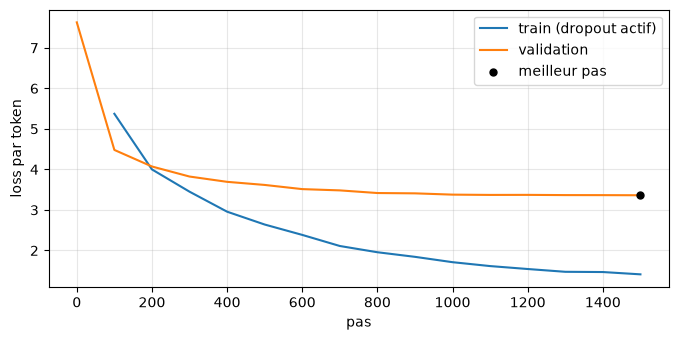

In [7]:
steps, train_curve, val_curve = zip(*result["history"])
plt.figure(figsize=(8, 3.6))
plt.plot(steps[1:], train_curve[1:], label="train (dropout actif)")
plt.plot(steps, val_curve, label="validation")
plt.scatter([result["best_step"]], [result["best_val"]], color="black", s=25, zorder=3, label="meilleur pas")
plt.xlabel("pas")
plt.ylabel("loss par token")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Le point de départ est la loss du modèle du notebook 06 sur ces comptines :
très haute, il n'en avait jamais vu. Le fine-tuning la fait chuter dès les
premières centaines de pas (7,6 → 3,7 en 400 pas), puis plafonne vers 3,36.
L'écart avec la courbe de train (1,4 à la fin) grandit : le modèle connaît
de mieux en mieux *ses* 1 600 comptines, sans progresser sur les autres.
Avec un corpus aussi petit, il ne servirait à rien d'aller plus loin. On
garde le modèle du meilleur pas de validation.

## 3. Écrire une comptine

### Arrêt après le 4ᵉ vers

`write_texts(..., n_lines=4)` (module `comptines.py`) compte les retours à la
ligne pendant la génération et arrête chaque texte à sa 4ᵉ fin de ligne (ou
à `<|endoftext|>`). Même si le modèle voulait continuer, la comptine fait au
plus 4 vers.

### Le meilleur de N

Le modèle tire chaque token au hasard : pour une même consigne, il écrit
chaque fois une comptine différente, plus ou moins réussie. `best_of_n` en
écrit `N` (en un seul lot, puisque les consignes sont identiques) et garde
celle qui a le meilleur score :

$$\text{score} = \text{mots-clés repris} + 0{,}5 \times \text{vers qui riment} - (1 \text{ si la comptine n'a pas 4 vers})$$

Le modèle ne change pas : seul le **choix** du texte change. C'est une
technique courante (*best-of-N*, *reranking*) : on dépense plus de calcul à
la génération pour un meilleur résultat. Regardons les 8 candidates d'une
consigne :

In [8]:
torch.manual_seed(SEED)
words = ["cat", "moon"]
best, candidates = best_of_n(model, tokenizer, words, n=8)
for text in sorted(candidates, key=lambda t: poem_score(words, t), reverse=True):
    print(f"score {poem_score(words, text):5.2f}   mots {keyword_hits(words, text):.0%}   rimes {rhyme_rate(text):.0%}")
    print("   " + text.replace("\n", "\n   "), end="\n\n")

score  1.00   mots 100%   rimes 0%
   There was a little girl, and she had a little cat;
   She threw it down against the moon, and it ran after it,
   And up she got it wet, and cold, and cold,
   And the little girl began for to shiver and sleep.

score  0.50   mots 50%   rimes 0%
   The moon was setting the moon
   And the moon was setting upon the wall;
   The birds were all singing,
   And the day came in.

score  0.50   mots 50%   rimes 0%
   Pussy cat and dog, where are you going?
   We'll go to the next house to see them a new one:
   We'll go to the new mill, to see them a one.
   We'll go to the new mill, to see all the new things.

score  0.00   mots 0%   rimes 0%
   Where was a good boy,
   Where do you think?
   I've nothing, I think,
   I've nothing but smile.

score  0.00   mots 0%   rimes 0%
   The air is cold, the worms are hid,
   And the worms are hid;
   They cannot find what to do.
   For what can be done.

score  0.00   mots 0%   rimes 0%
   I have a little cow,
 

## 4. La comparaison finale

Les quatre modèles du projet, sur les comptines de 4 vers de validation,
avec les **mêmes consignes** (mots-clés fixes, tirés avec l'IDF) :

| modèle | notebook |
|---|---|
| GPT caractère, entraîné sur les comptines | 02 |
| GPT BPE pré-entraîné sur TinyStories | 05 |
| + mots-clés renforcés (IDF) | 06 |
| + fine-tuning sur les comptines de 4 vers | 07 (ce notebook) |

### La loss en bits par caractère

On ne peut pas comparer directement une loss par caractère (modèle 02) et
une loss par token (les autres) : un token contient environ 4 caractères. On
ramène tout à la même unité, les **bits par caractère** : la loss totale de
la comptine (en nats, somme sur toutes ses positions notées) divisée par son
nombre de caractères, et par `ln 2` pour passer en bits. C'est le nombre
moyen de bits qu'il faudrait pour coder chaque caractère avec le modèle :
plus c'est bas, mieux le modèle prédit les comptines. Le coût du marqueur de
fin (`\n\n` ou `<|endoftext|>`) est compté dans la loss de chaque modèle.

In [9]:
@torch.no_grad()
def bits_per_char(model: nn.Module, dataset, texts: list[str]) -> float:
    """Loss totale (nats) sur toutes les positions notées du dataset, en bits par caractère des textes."""
    model.eval()
    total = 0.0
    for X, Y in DataLoader(dataset, batch_size=batch_size, sampler=SequentialSampler(dataset)):
        with autocast():
            _, loss = model(X.to(device), Y.to(device))
        total += loss.item() * (Y != -1).sum().item()
    return total / sum(len(t) for t in texts) / math.log(2)


def load_bpe(name: str) -> GPTLanguageModel:
    ckpt = torch.load(CHECKPOINT_DIR / name, map_location=device)
    m = GPTLanguageModel(**ckpt["config"]).to(device)
    m.load_state_dict(ckpt["model_state"])
    return m.eval()


char_ckpt = torch.load(CHECKPOINT_DIR / "gpt_comptines.pt", map_location=device)
char_tokenizer = CharTokenizer(char_ckpt["chars"])
char_model = GPTLanguageModel(**char_ckpt["config"]).to(device)
char_model.load_state_dict(char_ckpt["model_state"])
char_model.eval()

models = {
    "02 caractère": char_model,
    "05 pré-entraîné": load_bpe("gpt_bpe_preentraine.pt"),
    "06 mots-clés": load_bpe("gpt_bpe_mots_cles.pt"),
    "07 fine-tuné": model.eval(),
}
char_val = RhymeDataset(val_rhymes, char_tokenizer, 256, fixed_keywords=True)
bpc = {name: bits_per_char(m, char_val if name.startswith("02") else val_dataset, val_rhymes)
       for name, m in models.items()}
for name, value in bpc.items():
    print(f"{name:16} {value:.2f} bits par caractère")

02 caractère     2.15 bits par caractère
05 pré-entraîné  3.35 bits par caractère
06 mots-clés     3.40 bits par caractère
07 fine-tuné     1.50 bits par caractère


### Ce qu'écrivent les modèles

Pour chaque comptine de validation, chaque modèle écrit un texte à partir
des mêmes mots-clés, coupé à 4 vers (sans meilleur de N, sauf la dernière
ligne). On mesure :

- **mots repris** et sa **référence** (le texte écrit pour une autre consigne) ;
- **vers qui riment** ;
- **4 vers** : la part des textes qui ont bien 4 vers ;
- **mots par vers** : une comptine a des vers courts, une histoire des lignes
  qui sont des paragraphes.

In [10]:
keyword_sets = [val_dataset.keywords_of(i) for i in range(len(val_dataset))]
keyword_sets = [k for k in keyword_sets if k]


def cut(text: str) -> str:
    """Les 4 premiers vers non vides."""
    return "\n".join([line.strip() for line in text.split("\n") if line.strip()][:N_LINES])


def describe(texts: list[str]) -> dict[str, float]:
    """Les mesures d'un ensemble de textes générés pour `keyword_sets`."""
    n = len(texts)
    shifted = texts[1:] + texts[:1]
    lines = [[line for line in t.split("\n") if line.strip()] for t in texts]
    return {
        "mots repris": sum(keyword_hits(k, t) for k, t in zip(keyword_sets, texts)) / n,
        "référence": sum(keyword_hits(k, t) for k, t in zip(keyword_sets, shifted)) / n,
        "vers qui riment": sum(map(rhyme_rate, texts)) / n,
        "4 vers": sum(len(l) == N_LINES for l in lines) / n,
        "mots par vers": sum(len(line.split()) for l in lines for line in l) / max(1, sum(map(len, lines))),
    }


generated = {}
torch.manual_seed(SEED)
generated["02 caractère"] = [cut(write_rhyme(char_model, char_tokenizer, k)) for k in keyword_sets]
for name in ["05 pré-entraîné", "06 mots-clés", "07 fine-tuné"]:
    torch.manual_seed(SEED)
    generated[name] = write_texts(models[name], tokenizer, keyword_sets, n_lines=N_LINES, max_batch=64)

N_BEST = 8
torch.manual_seed(SEED)
pool = write_texts(model, tokenizer, [k for k in keyword_sets for _ in range(N_BEST)], n_lines=N_LINES, max_batch=64)
generated["07 + meilleur de 8"] = [max(pool[i * N_BEST : (i + 1) * N_BEST], key=lambda t: poem_score(k, t))
                                   for i, k in enumerate(keyword_sets)]
results = {name: describe(texts) for name, texts in generated.items()}

In [11]:
columns = ["mots repris", "référence", "vers qui riment", "4 vers", "mots par vers"]
print(f"{'modèle':20} {'bits/car.':>9} " + " ".join(f"{c:>15}" for c in columns))
for name, res in results.items():
    bpc_txt = f"{bpc[name]:9.2f}" if name in bpc else f"{'':9}"
    print(f"{name:20} {bpc_txt} " + " ".join(
        f"{res[c]:>15.1f}" if c == "mots par vers" else f"{res[c]:>15.1%}" for c in columns))
reference = describe(val_rhymes)
print(f"{'vraies comptines':20} {'':9} {'':>15} {'':>15} {reference['vers qui riment']:>15.1%} "
      f"{reference['4 vers']:>15.1%} {reference['mots par vers']:>15.1f}")

modèle               bits/car.     mots repris       référence vers qui riment          4 vers   mots par vers
02 caractère              2.15           15.0%            0.0%            5.4%           70.1%             7.9
05 pré-entraîné           3.35           14.4%            2.0%            2.3%           29.9%            40.3
06 mots-clés              3.40           15.6%            3.2%            2.6%           32.8%            40.9
07 fine-tuné              1.50            7.4%            1.8%            7.1%           87.4%             6.3
07 + meilleur de 8                       34.2%            0.6%           23.9%          100.0%             6.5
vraies comptines                                                         41.2%          100.0%             6.5


La dernière ligne donne les mêmes mesures sur les **vraies** comptines de
validation : c'est le niveau à viser pour les rimes et la longueur des vers.

## 5. Démonstration

Les consignes utilisées depuis le notebook 02, avec le modèle final et le
meilleur de 8 :

In [12]:
torch.manual_seed(SEED)
for words in [["cat", "moon"], ["king", "pie"], ["rain", "garden"], ["dog", "bone", "star"],
              ["girl", "ball", "happy"], ["mouse", "cheese"], ["sun", "sea", "boat"]]:
    best, _ = best_of_n(model, tokenizer, words, n=8)
    found = [w for w in words if keyword_hits([w], best)]
    print(f"--- {', '.join(words)}   (repris : {', '.join(found) or 'aucun'}, rimes {rhyme_rate(best):.0%}) ---")
    print(best, end="\n\n")

--- cat, moon   (repris : cat, moon, rimes 0%) ---
There was a little girl, and she had a little cat;
She threw it down against the moon, and it ran after it,
And up she got it wet, and cold, and cold,
And the little girl began for to shiver and sleep.



--- king, pie   (repris : king, rimes 0%) ---
Went to the world's in the land,
Went to see the king's day;
The queen was in the parlour
But then, oh, oh! the maid's at the crown!



--- rain, garden   (repris : garden, rimes 0%) ---
A sparrownet in the garden
Up upon a bough,
A tidy, &c.
A baby bunting in the pantry.



--- dog, bone, star   (repris : star, rimes 50%) ---
If a star it might blow,
What shall we do?
What time of day?  sea has come to us?
Or a world so.



--- girl, ball, happy   (repris : ball, rimes 0%) ---
There was an old woman, and what did you do,
She went to the ball and stole a bird's feather,
And stole it from her head,
And went to London to get less woman.



--- mouse, cheese   (repris : mouse, rimes 0%) ---
The fox when he came to the gate,
He was a little rat,
And he had but this poor Catskin,
He never would bark or mouse'd as fast as his tail.



--- sun, sea, boat   (repris : sun, sea, rimes 0%) ---
The sun was setting, the water was setting,
And the sea was setting,
And the sea was made of coal,
And the sea was setting, and the sea was setting.



## 6. Sauvegarder

Le modèle final, utilisé par `generer.py`.

In [13]:
torch.save({
    "model_state": model.state_dict(),
    "config": config,
    "gpt2_ids": tokenizer.gpt2_ids,
    "val_loss": result["best_val"],
    "history": result["history"],
    "results": results,
    "bits_per_char": bpc,
}, FINAL_PATH)
print(f"→ {FINAL_PATH.relative_to(ROOT)}")

→ checkpoints\gpt_comptines_final.pt
